# Стадия 6. Пайплайны, схемы проверки и альтернативные инструменты подбора

**Данные:** `data/processed/train_model.parquet` (результат стадии 1); описание набора — `README.md`.
**Предыдущие этапы:** `Stage_3_classification.ipynb` — базовая модель и порог решения;
`Stage_4_polynomial_regularization.ipynb` — полиномиальные признаки и штрафы;
`Stage_5_optuna.ipynb` — сетка против байесовской оптимизации.

**Цель стадии.** Собрать разрозненные приёмы проверки и подбора в один воспроизводимый
объект — пайплайн, — и на его основе ответить на три вопроса:

1. Насколько вообще устойчива оценка качества к случайности разбиения, и какие из
   полученных в стадиях 3–5 приростов превышают этот шум.
2. Какие схемы проверки применимы к бинарной цели `Event` (0 — пациент жив со своей
   печенью, 1 — трансплантация или смерть) и чем они различаются.
3. Чем отличаются четыре инструмента подбора гиперпараметров — полный перебор, случайный
   поиск, ранний отсев и их комбинация — на одинаковых данных, одинаковой схеме проверки
   и одинаковом критерии.

**Итог стадии.** Рекомендация модели к применению с обоснованием: качество, устойчивость
и цена подбора.

**Зачем это нужно.** В стадиях 4 и 5 стандартизация выполнялась до разбиения на блоки
кросс-валидации, а матрицы признаков готовились вручную для каждой степени полинома.
Приём рабочий, но он не оформлен в единый объект и требует ручной пересборки при каждом
переносе модели в эксплуатацию. Пайплайн решает обе задачи: все преобразования
выполняются внутри каждого блока проверки и переносятся вместе с моделью.


## **1. Импорты и настройки**

In [1]:
# Сторонние библиотеки
import os
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform, uniform
# HalvingGridSearchCV и HalvingRandomSearchCV в scikit-learn 1.9 помечены как экспериментальные:
# импорт enable_halving_search_cv должен предшествовать импорту самих классов
from sklearn.experimental import enable_halving_search_cv   # noqa: F401
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
                             f1_score, log_loss, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, HalvingGridSearchCV,
                                     HalvingRandomSearchCV, KFold, LeaveOneOut,
                                     RandomizedSearchCV, RepeatedStratifiedKFold,
                                     StratifiedKFold, cross_val_score,
                                     cross_val_predict, cross_validate,
                                     train_test_split)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

# Единое зерно случайности для всего ноутбука: выборки, разбиения, кросс-валидация.
# Значение не меняется между прогонами и стадиями, поэтому результаты сравнимы.
RANDOM_STATE = 42


## **2. Данные и точка отсчёта**

Матрица, разбиение и зерно — те же, что в стадиях 3, 4 и 5: 15 отобранных признаков,
бинарная цель `Event`, контрольная часть 25 %, стратификация по цели, `RANDOM_STATE = 42`.
Отличие стадии 6: стандартизация больше не выполняется вручную, она внутри пайплайна.
Базовая модель воспроизводится и сверяется с числами стадии 3 — это подтверждает, что
пайплайн эквивалентен ручной предобработке и сравнение со всеми предыдущими стадиями корректно.


In [2]:
# Корень проекта: папка с data/, найденная вверх по дереву от текущей директории
def find_project_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(d, 'data')):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            raise FileNotFoundError('Папка data/ не найдена вверх по дереву от ' + d)
        d = parent


PROJECT_ROOT = find_project_root()
df = pd.read_parquet(os.path.join(PROJECT_ROOT, 'data', 'processed', 'train_model.parquet'))
assert df.shape == (7905, 16), 'Ожидается матрица 7 905 x 16 из стадии 1'
assert df.isna().sum().sum() == 0, 'В матрице модели не должно быть пропусков'

X = df.drop(columns=['Event']).astype(float)
y = df['Event'].astype(int)
assert X.shape[1] == 15, 'В матрице должно быть 15 отобранных признаков'
assert sorted(y.unique()) == [0, 1], 'Цель должна быть бинарной'

# Основное разбиение — то же, что в стадиях 3, 4 и 5
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
print('Обучающая часть:', X_train.shape[0], 'строк / контрольная:', X_test.shape[0])
print('Событий в контрольной части:', int(y_test.sum()), 'из', len(y_test))


def evaluate(model, X_eval, y_eval, tag):
    # Набор метрик бинарной классификации — тот же, что в стадиях 3, 4 и 5.
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)[:, 1]
    return {
        'вариант': tag,
        'ROC-AUC': roc_auc_score(y_eval, y_proba),
        'PR-AUC': average_precision_score(y_eval, y_proba),
        'метрика Брайера': brier_score_loss(y_eval, y_proba),
        'лог-потеря': log_loss(y_eval, y_proba),
        'F-мера': f1_score(y_eval, y_pred),
        'полнота': recall_score(y_eval, y_pred),
        'точность': precision_score(y_eval, y_pred),
        'доля верных ответов': accuracy_score(y_eval, y_pred),
    }


def base_pipeline():
    # Точка отсчёта: стандартизация + логистическая регрессия на исходных 15 признаках.
    return make_pipeline(StandardScaler(),
                         LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))


base = base_pipeline().fit(X_train, y_train)
base_row = evaluate(base, X_test, y_test, 'базовая (стадия 3)')

# Сверка со стадией 3: то же разбиение, то же зерно, та же модель
STAGE3_REFERENCE = {
    'ROC-AUC': 0.8788,
    'PR-AUC': 0.8132,
    'метрика Брайера': 0.1333,
    'лог-потеря': 0.4257,
    'F-мера': 0.7307,
    'полнота': 0.6830,
    'точность': 0.7856,
    'доля верных ответов': 0.8128,
}
for metric, expected in STAGE3_REFERENCE.items():
    actual = base_row[metric]
    assert abs(actual - expected) < 5e-4, f'{metric}: {actual:.4f} против {expected} в стадии 3'
print('Метрики совпали со стадией 3: пайплайн эквивалентен ручной стандартизации.')
display(pd.DataFrame([base_row]).set_index('вариант').round(4))


Обучающая часть: 5928 строк / контрольная: 1977
Событий в контрольной части: 735 из 1977
Метрики совпали со стадией 3: пайплайн эквивалентен ручной стандартизации.


,ROC-AUC,PR-AUC,метрика Брайера,лог-потеря,F-мера,полнота,точность,доля верных ответов
вариант,,,,,,,,
базовая (стадия 3),0.8788,0.8132,0.1333,0.4257,0.7307,0.683,0.7856,0.8128


### Вывод по точке отсчёта

Точка отсчёта — пайплайн из двух шагов: стандартизация и логистическая регрессия
на исходных 15 признаках, без полиномов и без подбора параметров. Все восемь метрик
воспроизвели стадию 3 с точностью до четвёртого знака: ROC-AUC **0.8788**, PR-AUC
**0.8132**, метрика Брайера **0.1333**, лог-потеря **0.4257**, F-мера **0.7307**,
полнота **0.6830**, точность **0.7856**, доля верных ответов **0.8128**.

Совпадение проверено `assert` по всем восьми метрикам, поэтому дальнейшее сравнение
со стадиями 3, 4 и 5 корректно: различия будут отражать свойства моделей,
а не способ предобработки.


## **3. Насколько устойчива оценка: двадцать разбиений**

Прежде чем сравнивать модели между собой, нужно понять, чего стоит сама цифра. Одно
разбиение 75/25 — это одна конкретная жеребёвка: 1 977 строк контрольной части выпали
из 7 905 случайным образом. Возьмём ту же модель, те же данные и повторим разбиение
двадцать раз с разными зернами. Если прирост, полученный в стадиях 3–5, меньше размаха
этих двадцати значений, сравнивать варианты по одному числу некорректно.


In [3]:
SEEDS = list(range(20))
METRICS = ['доля верных ответов', 'ROC-AUC', 'лог-потеря', 'F-мера', 'полнота']

split_rows = []
for seed in SEEDS:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.25, stratify=y, random_state=seed
    )
    model = base_pipeline().fit(X_tr, y_tr)
    row = evaluate(model, X_te, y_te, 'модель')
    row['seed'] = seed
    split_rows.append(row)

splits = pd.DataFrame(split_rows).set_index('seed')[METRICS]

summary = pd.DataFrame({
    'минимум': splits.min(),
    'среднее': splits.mean(),
    'максимум': splits.max(),
    'разброс (max - min)': splits.max() - splits.min(),
    'стандартное отклонение': splits.std(),
}).round(4)
display(summary)

print(f'Разбиений: {len(SEEDS)}, модель и данные неизменны, отличается только жеребёвка')
for metric in METRICS:
    print(f'{metric}: {splits[metric].min():.4f} ... {splits[metric].max():.4f} | '
          f'разброс {splits[metric].max() - splits[metric].min():.4f} | '
          f'ср. квадратичное отклонение {splits[metric].std():.4f}')

main_acc = base_row['доля верных ответов']
main_loss = base_row['лог-потеря']
print(f'Основное разбиение (seed {RANDOM_STATE}): доля верных ответов {main_acc:.4f}, '
      f'лог-потеря {main_loss:.4f}')
print(f'Хуже основного разбиения по доле верных ответов: '
      f'{int((splits["доля верных ответов"] < main_acc).sum())} из {len(SEEDS)}')
print(f'Хуже основного разбиения по лог-потере: '
      f'{int((splits["лог-потеря"] > main_loss).sum())} из {len(SEEDS)}')


,минимум,среднее,максимум,разброс (max - min),стандартное отклонение
доля верных ответов,0.8093,0.8188,0.8280,0.0187,0.0049
ROC-AUC,0.8677,0.8803,0.8965,0.0288,0.0072
лог-потеря,0.3954,0.4183,0.4380,0.0427,0.0105
F-мера,0.7209,0.7377,0.7543,0.0334,0.0083
полнота,0.6612,0.6855,0.7129,0.0517,0.0150


Разбиений: 20, модель и данные неизменны, отличается только жеребёвка
доля верных ответов: 0.8093 ... 0.8280 | разброс 0.0187 | ср. квадратичное отклонение 0.0049
ROC-AUC: 0.8677 ... 0.8965 | разброс 0.0288 | ср. квадратичное отклонение 0.0072
лог-потеря: 0.3954 ... 0.4380 | разброс 0.0427 | ср. квадратичное отклонение 0.0105
F-мера: 0.7209 ... 0.7543 | разброс 0.0334 | ср. квадратичное отклонение 0.0083
полнота: 0.6612 ... 0.7129 | разброс 0.0517 | ср. квадратичное отклонение 0.0150
Основное разбиение (seed 42): доля верных ответов 0.8128, лог-потеря 0.4257
Хуже основного разбиения по доле верных ответов: 2 из 20
Хуже основного разбиения по лог-потере: 5 из 20


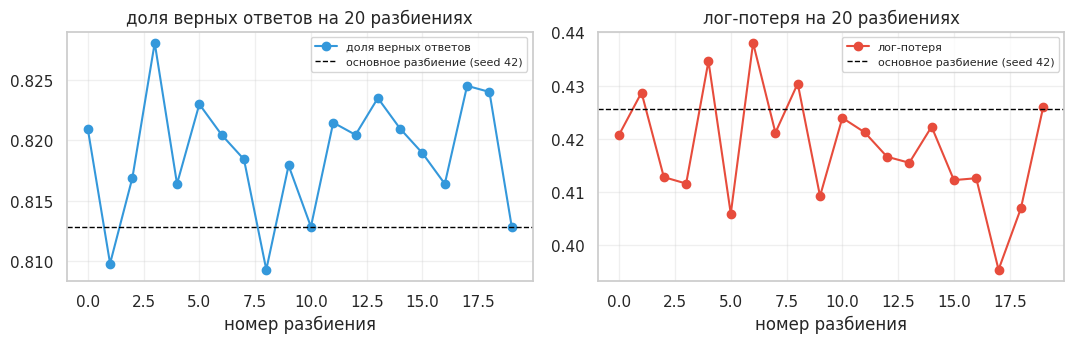

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, metric, color in [(axes[0], 'доля верных ответов', '#3498db'),
                          (axes[1], 'лог-потеря', '#e74c3c')]:
    ax.plot(SEEDS, splits[metric], marker='o', color=color, label=metric)
    ax.axhline(base_row[metric], ls='--', color='black', lw=1,
               label=f'основное разбиение (seed {RANDOM_STATE})')
    ax.set_xlabel('номер разбиения')
    ax.set_title(f'{metric} на 20 разбиениях')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Вывод по разбросу оценки

| Метрика | Минимум | Среднее | Максимум | Разброс | Ср. квадратичное отклонение |
|---|---|---|---|---|---|
| Доля верных ответов | 0.8093 | 0.8188 | 0.8280 | 0.0187 | 0.0049 |
| ROC-AUC | 0.8677 | 0.8803 | 0.8965 | 0.0288 | 0.0072 |
| Лог-потеря | 0.3954 | 0.4183 | 0.4380 | 0.0427 | 0.0105 |
| F-мера | 0.7209 | 0.7377 | 0.7543 | 0.0334 | 0.0083 |
| Полнота | 0.6612 | 0.6855 | 0.7129 | 0.0517 | 0.0150 |

Основное разбиение (seed 42) дало долю верных ответов 0.8128 и лог-потерю 0.4257.
По доле верных ответов оно хуже 2 разбиений из 20, по лог-потере — хуже 5 из 20.

Разброс лог-потери по разбиениям (**0.0427**) в 3.6 раза больше расхождения между
инструментами подбора (**0.0120**), которое будет найдено в блоке 12. Разброс полноты
(**0.0517**) больше, чем разница между лучшей и худшей моделью на контрольной части.
Одно разбиение не различает варианты такого масштаба.


## **4. Три выборки вместо двух**

Классическая схема делит данные на обучение и контроль. Но тогда настройка модели
(выбор степени полинома, силы штрафа, порога) тоже опирается на контрольную часть,
и она постепенно «подогревается» решениями аналитика. Строгая схема — три части:
обучение, валидация для настройки и разовая контрольная оценка.

Контрольную часть оставляем того же размера, что во всех предыдущих стадиях (25 %),
иначе цифры будут несопоставимы. Значит, валидация берётся из обучающей части:
50 % обучение, 25 % валидация, 25 % контроль. Считаем цену такого решения.


In [5]:
# 50 % / 25 % / 25 %: контрольная часть того же размера, что в стадиях 3-5
X_tr3, X_rest, y_tr3, y_rest = train_test_split(
    X, y, test_size=0.50, stratify=y, random_state=RANDOM_STATE
)
X_va3, X_te3, y_va3, y_te3 = train_test_split(
    X_rest, y_rest, test_size=0.50, stratify=y_rest, random_state=RANDOM_STATE
)

print(f'обучение:   {len(X_tr3)} строк ({len(X_tr3) / len(X):.0%}), событий: {int(y_tr3.sum())}')
print(f'валидация:  {len(X_va3)} строк ({len(X_va3) / len(X):.0%}), событий: {int(y_va3.sum())}')
print(f'контроль:   {len(X_te3)} строк ({len(X_te3) / len(X):.0%}), событий: {int(y_te3.sum())}')

model3 = base_pipeline().fit(X_tr3, y_tr3)
three_rows = [evaluate(model3, part, target, name)
              for name, part, target in [('обучение', X_tr3, y_tr3),
                                         ('валидация', X_va3, y_va3),
                                         ('контроль', X_te3, y_te3)]]
three = pd.DataFrame(three_rows).set_index('вариант')
display(three.round(4))

lost = len(X_train) - len(X_tr3)
print(f'Строк для обучения: {len(X_tr3)} против {len(X_train)} при схеме 75/25 — '
      f'потеряно {lost} строк ({lost / len(X_train):.0%} обучающей части)')
print(f'Разрыв «обучение - контроль» по лог-потере: '
      f'{three.loc["контроль", "лог-потеря"] - three.loc["обучение", "лог-потеря"]:.4f}')


обучение:   3952 строк (50%), событий: 1470
валидация:  1976 строк (25%), событий: 735
контроль:   1977 строк (25%), событий: 735


,ROC-AUC,PR-AUC,метрика Брайера,лог-потеря,F-мера,полнота,точность,доля верных ответов
вариант,,,,,,,,
обучение,0.8808,0.8271,0.1311,0.4155,0.7404,0.6925,0.7953,0.8193
валидация,0.8825,0.8296,0.1315,0.4148,0.7228,0.6653,0.7913,0.8102
контроль,0.8715,0.8049,0.1359,0.4352,0.7249,0.6721,0.7866,0.8103


Строк для обучения: 3952 против 5928 при схеме 75/25 — потеряно 1976 строк (33% обучающей части)
Разрыв «обучение - контроль» по лог-потере: 0.0197


### Вывод по третьей выборке

| Часть | Строк | Событий | ROC-AUC | Лог-потеря | F-мера | Полнота | Доля верных ответов |
|---|---|---|---|---|---|---|---|
| обучение | 3 952 | 1 470 | 0.8808 | 0.4155 | 0.7404 | 0.6925 | 0.8193 |
| валидация | 1 976 | 735 | 0.8825 | 0.4148 | 0.7228 | 0.6653 | 0.8102 |
| контроль | 1 977 | 735 | 0.8715 | 0.4352 | 0.7249 | 0.6721 | 0.8103 |

Цена третьей выборки — **1 976 строк** (33 % обучающей части), которые ушли
из обучения. Разрыв «обучение − контроль» по лог-потере **0.0197** — это оптимизм
оценки на собственных строках, а не переобучение: модель на 3 952 строках показала
наружу лишь немного хуже, чем внутрь.

Валидация и контроль дают близкие числа (0.4148 и 0.4352) при том, что валидация
использовалась для настроечных решений. Контрольная часть оказалась строже — на ней
лог-потеря выше на 0.0204. Разделение на три части не гарантирует независимости
контроля, но снимает основную проблему — привыкание к одной и той же выборке
при каждой следующей настройке.


## **5. Схемы кросс-валидации**

Кросс-валидация заменяет отдельную валидационную выборку: обучающая часть несколько раз
делится на блоки, и каждый побывает ролью проверки по очереди. Выбор схемы определяет,
насколько оценка близка к будущей реальности. Разберём четыре варианта на наших данных.


### **5.1 KFold против StratifiedKFold**

Обычный `KFold` делит строки наугад, `StratifiedKFold` сохраняет долю каждого класса.
С бинарной целью риск потерять класс в блоке проверки почти исчез: событий 37.2 %,
и даже случайное деление оставляет в блоке сотни событий. Различие между схемами
теперь не в наличии класса, а в точности, с которой воспроизводится его доля.
Проверим, насколько это различие существенно.


In [6]:
shares = {'KFold': [], 'StratifiedKFold': []}

for name, cv in [('KFold', KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)),
                 ('StratifiedKFold', StratifiedKFold(n_splits=5, shuffle=True,
                                                      random_state=RANDOM_STATE))]:
    for _, val_idx in cv.split(X_train, y_train):
        shares[name].append(float(y_train.iloc[val_idx].mean()))

fold_table = pd.DataFrame({
    'доля событий по пяти блокам': [np.round(shares[n], 5).tolist() for n in shares],
    'минимальная доля': [min(shares[n]) for n in shares],
    'разброс (ср. квадратичное)': [np.std(shares[n]) for n in shares],
}, index=list(shares.keys()))
display(fold_table.round(5))

n_ev_train = int(y_train.sum())
print(f'События в обучающей части: {n_ev_train} строк ({y_train.mean():.4%})')
print(f'В среднем на один блок проверки при 5 блоках: {n_ev_train / 5:.0f} строк')
print(f'Разброс доли событий: KFold {np.std(shares["KFold"]):.6f} против '
      f'StratifiedKFold {np.std(shares["StratifiedKFold"]):.6f}')
print(f'Наименьшая доля событий в блоке: KFold {min(shares["KFold"]):.5f} против '
      f'StratifiedKFold {min(shares["StratifiedKFold"]):.5f}')


,доля событий по пяти блокам,минимальная доля,разброс (ср. квадратичное)
KFold,"[0.36931, 0.37352, 0.37184, 0.37975, 0.3654]",0.36540,0.00476
StratifiedKFold,"[0.37184, 0.37184, 0.37184, 0.37215, 0.37215]",0.37184,0.00015


События в обучающей части: 2205 строк (37.1964%)
В среднем на один блок проверки при 5 блоках: 441 строк
Разброс доли событий: KFold 0.004757 против StratifiedKFold 0.000154
Наименьшая доля событий в блоке: KFold 0.36540 против StratifiedKFold 0.37184


### **5.2 LeaveOneOut: почему не применяем**

Предельный случай кросс-валидации — `LeaveOneOut`: модель обучается столько раз, сколько
строк в обучающей части, каждый раз проверяясь на одной строке. Оценка формально самая
точная, но цена растёт пропорционально числу строк. Сравним её с пятью блоками на маленькой
выборке в 200 строк (там прогон реален), а затем посчитаем цену на всей обучающей части.


In [7]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
loo = LeaveOneOut()

# 1. Реальный прогон на маленькой выборке: 200 строк, 200 обучений против 5.
#    Метрика — доля верных ответов: в блоке проверки одна строка, поэтому лог-потеря
#    не определена (в примере ниже это показано отдельно).
idx_small = X_train.sample(n=200, random_state=RANDOM_STATE).index
X_small, y_small = X_train.loc[idx_small], y_train.loc[idx_small]
cv5_small = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

started = time.time()
res_loo = cross_val_score(base_pipeline(), X_small, y_small, cv=loo, scoring='accuracy')
t_loo_small = time.time() - started

started = time.time()
res_5_small = cross_val_score(base_pipeline(), X_small, y_small, cv=cv5_small,
                              scoring='accuracy')
t_5_small = time.time() - started

print('--- маленькая выборка: 200 строк ---')
print(f'LeaveOneOut: {len(res_loo)} обучений за {t_loo_small:.2f} с, '
      f'доля верных ответов {res_loo.mean():.4f}')
print(f'Пять блоков: {len(res_5_small)} обучений за {t_5_small:.2f} с, '
      f'доля верных ответов {res_5_small.mean():.4f}')
print(f'Разница в оценке: {abs(res_loo.mean() - res_5_small.mean()):.4f} при цене '
      f'в {len(res_loo) / len(res_5_small):.0f} раз выше')

try:
    cross_val_score(base_pipeline(), X_small, y_small, cv=loo,
                    scoring='neg_log_loss', error_score='raise')
    print('Лог-потеря с LeaveOneOut вычислилась')
except ValueError as err:
    print(f'Лог-потеря с LeaveOneOut не вычисляется: {err}')

# 2. Цена на полной обучающей части. Обучение LeaveOneOut использует n - 1 строк из n,
#    то есть почти столько же, сколько блок обычной схемы, поэтому время считаем
#    пропорциональным числу обучений: это нижняя граница, без накладных расходов прогона.
n_loo = loo.get_n_splits(X_train)
n_5fold = cv5.get_n_splits(X_train)

started = time.time()
_ = cross_val_score(base_pipeline(), X_train, y_train, cv=cv5,
                    scoring='accuracy', n_jobs=-1)
t_5fold = time.time() - started
t_loo_full = t_5fold * n_loo / n_5fold

print('--- полная обучающая часть ---')
print(f'Пять блоков: {n_5fold} обучений за {t_5fold:.2f} с')
print(f'LeaveOneOut: {n_loo} обучений, оценка времени: {t_loo_full / 60:.1f} мин')
print(f'Во сколько раз больше обучений: {n_loo / n_5fold:.0f}')
print(f'Строк в блоке проверки: пять блоков — {len(X_train) // 5}, LeaveOneOut — 1')

--- маленькая выборка: 200 строк ---
LeaveOneOut: 200 обучений за 0.99 с, доля верных ответов 0.8050
Пять блоков: 5 обучений за 0.04 с, доля верных ответов 0.8000
Разница в оценке: 0.0050 при цене в 40 раз выше
Лог-потеря с LeaveOneOut не вычисляется: y_true contains only one label (1). Please provide the list of all expected class labels explicitly through the labels argument.


--- полная обучающая часть ---
Пять блоков: 5 обучений за 2.35 с
LeaveOneOut: 5928 обучений, оценка времени: 46.4 мин
Во сколько раз больше обучений: 1186
Строк в блоке проверки: пять блоков — 1185, LeaveOneOut — 1


### **5.3 RepeatedStratifiedKFold: уточнение оценки**

`RepeatedStratifiedKFold` повторяет всю схему k-fold несколько раз с разными зернами.
Он не улучшает модель — он улучшает знание о ней: средняя оценка становится устойчивее,
а разброс между блоками позволяет понять, насколько цифре можно доверять. Сравниваем
5 блоков и 5 блоков на пять повторов (25 обучений).


In [8]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

rows = []
for name, cv in [('пять блоков', skf), ('пять блоков x 5 повторов', rskf)]:
    started = time.time()
    res = cross_validate(base_pipeline(), X_train, y_train, cv=cv,
                         scoring='neg_log_loss', return_train_score=True, n_jobs=-1)
    elapsed = time.time() - started
    test = -res['test_score']
    rows.append({
        'схема': name,
        'обучений': len(test),
        'лог-потеря (среднее)': test.mean(),
        'разброс между блоками': test.std(),
        'ошибка среднего': test.std() / np.sqrt(len(test)),
        'время, с': elapsed,
    })

rep_table = pd.DataFrame(rows).set_index('схема')
display(rep_table.round(4))

se_5 = rep_table.loc['пять блоков', 'ошибка среднего']
se_25 = rep_table.loc['пять блоков x 5 повторов', 'ошибка среднего']
n_5 = rep_table.loc['пять блоков', 'обучений']
n_25 = rep_table.loc['пять блоков x 5 повторов', 'обучений']
t_25 = rep_table.loc['пять блоков x 5 повторов', 'время, с']
print(f'Оценка среднего уточнилась в {se_5 / se_25:.2f} раза')
print(f'Ценой: {n_25 / n_5:.0f} раз большего числа обучений ({n_5} против {n_25}) '
      f'и {t_25:.1f} с вместо {t_5fold:.1f} с')
print(f'Лог-потеря: пять блоков {rep_table.loc["пять блоков", "лог-потеря (среднее)"]:.4f}, '
      f'повторы {rep_table.loc["пять блоков x 5 повторов", "лог-потеря (среднее)"]:.4f}')

,обучений,лог-потеря (среднее),разброс между блоками,ошибка среднего,"время, с"
схема,,,,,
пять блоков,5,0.4204,0.0253,0.0113,1.7602
пять блоков x 5 повторов,25,0.4202,0.0159,0.0032,1.8884


Оценка среднего уточнилась в 3.55 раза
Ценой: 5 раз большего числа обучений (5 против 25) и 1.9 с вместо 2.3 с
Лог-потеря: пять блоков 0.4204, повторы 0.4202


### Вывод по схемам кросс-валидации

**Стратификация выравнивает блоки.** Доли события по пяти блокам:

| Схема | Доли события по блокам | Наименьшая доля | Разброс (std) |
|---|---|---|---|
| `KFold` | 0.36931, 0.37352, 0.37184, 0.37975, 0.36540 | 0.36540 | **0.00476** |
| `StratifiedKFold` | 0.37184, 0.37184, 0.37184, 0.37215, 0.37215 | 0.37184 | **0.00015** |

`StratifiedKFold` держит долю события в 31 раз стабильнее. В обучающей части 2 205
событий (37.1964 %) — это около **441 строки** на блок проверки. При `KFold` разброс
доли составляет 0.0048, то есть до пяти событий на тысячу строк блока. На оценке
лог-потери это сказывается слабее, чем различия между моделями, но схема с гарантией
всё равно предпочтительнее.

**LeaveOneOut не окупается.** На 200 строках: 200 обучений за **0.99 с** против
5 обучений за **0.04 с** — доля верных ответов **0.8050** против **0.8000**,
разница **0.0050** при цене в **40 раз**. Лог-потеря для LeaveOneOut вообще
не вычисляется: в блоке проверки остаётся одна строка с одной меткой.
На полной обучающей части это **5 928 обучений**, оценка времени — **46.4 минуты**
против **2.35 с**, то есть в **1 186 раз** больше обучений.

**Повторы дают точность оценки, а не модели.** `RepeatedStratifiedKFold`
(5 повторов × 5 блоков, 25 обучений) дал ту же среднюю лог-потерю — **0.4202** против
**0.4204**, — но ошибка среднего упала с **0.0113** до **0.0032**: уточнение в **3.55 раза**
ценой пятикратного числа обучений (5 против 25) и 1.9 с вместо 2.3 с.

Вывод: для этой задачи рабочая схема — `StratifiedKFold` на пять блоков.


## **6. Пайплайн: преобразования внутри проверки**

`Pipeline` собирает предобработку и модель в один объект. При кросс-валидации каждый блок
данных проходит через преобразования, обученные только на строках текущего блока обучения.
Это закрывает утечку: статистики, посчитанные по всем строкам сразу, «подглядывают» в те
данные, которые в этой итерации играют роль проверки.

В стадиях 4 и 5 стандартизация выполнялась один раз на всей обучающей части до кросс-валидации.
Сейчас сравним обе оценки численно — на полной обучающей части и на маленькой выборке,
где утечка заметнее.


In [9]:
def cv_logloss_external(X_part, y_part, cv, steps='scale'):
    # Вариант «как в стадиях 4-5»: преобразование обучается ДО разбиения на блоки,
    # то есть по всем строкам сразу, включая те, что в этой итерации проверяются.
    if steps == 'scale':
        transformed = StandardScaler().fit_transform(X_part)
    else:
        # Отбор признаков по связи с целью: здесь преобразование смотрит на y
        # всех строк сразу — утечка становится содержательной, а не численной.
        transformed = SelectKBest(f_classif, k=8).fit_transform(X_part, y_part)
    model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    return -cross_val_score(model, transformed, y_part, cv=cv,
                             scoring='neg_log_loss').mean()


def cv_logloss_piped(X_part, y_part, cv, steps='scale'):
    # Тот же приём внутри пайплайна: обучается только на строках текущего блока.
    if steps == 'scale':
        pipe = base_pipeline()
    else:
        pipe = make_pipeline(StandardScaler(), SelectKBest(f_classif, k=8),
                             LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    return -cross_val_score(pipe, X_part, y_part, cv=cv, scoring='neg_log_loss').mean()


leak_rows = []
for n_rows in [len(X_train), 300]:
    if n_rows == len(X_train):
        X_part, y_part = X_train, y_train
    else:
        idx = X_train.sample(n=n_rows, random_state=RANDOM_STATE).index
        X_part, y_part = X_train.loc[idx], y_train.loc[idx]
    cv_small = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    for steps, label in [('scale', 'стандартизация'),
                         ('select', 'стандартизация + отбор 8 признаков по цели')]:
        ext = cv_logloss_external(X_part, y_part, cv_small, steps)
        pip = cv_logloss_piped(X_part, y_part, cv_small, steps)
        leak_rows.append({'строк': n_rows, 'преобразование': label,
                          'снаружи (утечка)': ext, 'в пайплайне': pip,
                          'разница': ext - pip})

leak = pd.DataFrame(leak_rows).set_index(['строк', 'преобразование'])
display(leak.round(5))
print('Отрицательная разница означает, что оценка с внешним преобразованием оптимистичнее')

снаружи (утечка)  в пайплайне  разница
строк преобразование                                                                    
5928  стандартизация                                       0.42044      0.42044  0.00000
      стандартизация + отбор 8 признаков по цели           0.42715      0.42717 -0.00001
300   стандартизация                                       0.48710      0.48725 -0.00015
      стандартизация + отбор 8 признаков по цели           0.47420      0.48578 -0.01158

Отрицательная разница означает, что оценка с внешним преобразованием оптимистичнее


### Вывод по утечке масштабирования

Лог-потеря на кросс-валидации при разном порядке операций:

| Строк | Преобразование | Снаружи (утечка) | В пайплайне | Разница |
|---|---|---|---|---|
| 5 928 | стандартизация | 0.42044 | 0.42044 | 0.00000 |
| 5 928 | стандартизация + отбор 8 признаков по цели | 0.42715 | 0.42717 | −0.00001 |
| 300 | стандартизация | 0.48710 | 0.48725 | −0.00015 |
| 300 | стандартизация + отбор 8 признаков по цели | **0.47420** | **0.48578** | **−0.01158** |

**Масштабирование само по себе утечки не даёт.** `StandardScaler` использует только
среднее и разброс признаков, метку класса он не видит. На 5 928 строках разница
**0.00000**, на 300 — **−0.00015**, то есть оценка совпадает с точностью до четвёртого знака.

**Опасен отбор по цели.** Когда `SelectKBest(f_classif)` обучается на всех строках
вместе с метками, он заранее знает, какие столбцы разделяют событие и его отсутствие.
На 300 строках это выглядело как улучшение: **0.47420** против честных **0.48578**,
разрыв **−0.01158**. Отрицательная разница означает, что оценка с внешним
преобразованием оптимистична — реальные показатели будут хуже показанных.

Чем меньше данных, тем сильнее эффект: на 5 928 строках отбор по цели искажал оценку
на **−0.00001**, на 300 — уже на **−0.01158**. Предобработка обязана быть внутри
пайплайна: тогда в каждом блоке проверки она обучается только на строках этого блока.


In [10]:
poly_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('model', LogisticRegression(solver='saga', max_iter=5000, tol=1e-3,
                                 random_state=RANDOM_STATE)),
])
print('Шаги пайплайна:', [name for name, _ in poly_pipe.steps])

poly_pipe.fit(X_train, y_train)
poly_row = evaluate(poly_pipe, X_test, y_test, 'полином 2 ст. без штрафа (пайплайн)')

n_out = len(poly_pipe['poly'].get_feature_names_out())
print(f'Признаков: было {X_train.shape[1]}, стало {n_out}')
print('Квадраты бинарных признаков не удалялись: x^2 совпадает с x, '
      'в стадии 4 их убирали вручную (132 столбца), здесь 135')

pipe_rows = [base_row, poly_row]
display(pd.DataFrame(pipe_rows).set_index('вариант').round(4))

cv_pipe_loss = -cross_val_score(poly_pipe, X_train, y_train, cv=skf,
                                scoring='neg_log_loss', n_jobs=-1).mean()
print(f'Лог-потеря пайплайна с полиномом на пяти блоках обучающей части: {cv_pipe_loss:.4f}')
print(f'Лог-потеря базового пайплайна на пяти блоках: '
      f'{-cross_val_score(base_pipeline(), X_train, y_train, cv=skf, scoring="neg_log_loss", n_jobs=-1).mean():.4f}')

Шаги пайплайна: ['scaler', 'poly', 'model']


Признаков: было 15, стало 135
Квадраты бинарных признаков не удалялись: x^2 совпадает с x, в стадии 4 их убирали вручную (132 столбца), здесь 135


,ROC-AUC,PR-AUC,метрика Брайера,лог-потеря,F-мера,полнота,точность,доля верных ответов
вариант,,,,,,,,
базовая (стадия 3),0.8788,0.8132,0.1333,0.4257,0.7307,0.6830,0.7856,0.8128
полином 2 ст. без штрафа (пайплайн),0.8770,0.8166,0.1352,0.4294,0.7373,0.7197,0.7557,0.8093


Лог-потеря пайплайна с полиномом на пяти блоках обучающей части: 0.4178
Лог-потеря базового пайплайна на пяти блоках: 0.4204


### Вывод по пайплайну с полиномиальными признаками

Пайплайн `scaler → poly → model` собрал три шага в один объект. На контрольной
части вариант «полином 2 ст. без штрафа» дал ROC-AUC **0.8770**, PR-AUC **0.8166**,
метрику Брайера **0.1352**, лог-потерю **0.4294**, F-меру **0.7373**, полноту **0.7197**,
точность **0.7557** и долю верных ответов **0.8093**.

Признаков стало **135** вместо 15. Квадраты бинарных признаков не удалены:
`x^2` совпадает с `x`, поэтому в стадии 4 после ручной чистки было 132 столбца,
а здесь — 135. Три лишних столбца не ломают модель, но штраф в `LogisticRegression`
тратит ёмкость на дубликаты.

Картина смешанная. F-мера и полнота выросли заметно (0.7373 против 0.7307 и 0.7197
против 0.6830), PR-AUC тоже (0.8166 против 0.8132). Лог-потеря и ROC-AUC ухудшились
(0.4294 против 0.4257 и 0.8770 против 0.8788): без регуляризации модель из 135 столбцов
переоценивает уверенность и хуже упорядочивает объекты. На кросс-валидации по обучающей
части полином немного лучше базового пайплайна (**0.4178** против **0.4204**) — выигрыш
без штрафа держится на обучающих строках и меняет знак на новых.

Вторая степень сама по себе качества не улучшает — ей нужен штраф, что и проверяется дальше.


## **7. Условия сравнения инструментов подбора**

Все четыре инструмента работают в одинаковых условиях, иначе сравнение бессмысленно:

| Условие | Значение |
|---|---|
| Объект подбора | один пайплайн: стандартизация, полином, логистическая регрессия |
| Пространство | степень полинома (1, 2) x `l1_ratio` (5 значений) x `C` (8 значений) — 80 комбинаций |
| Схема проверки | `StratifiedKFold`, пять блоков, зерно `RANDOM_STATE` |
| Критерий | лог-потеря на кросс-валидации (минимизируется) |
| Данные | только обучающая часть; контрольная не участвует в подборе |

Степень полинома впервые стала обычным гиперпараметром `poly__degree`: в стадии 5 для этого
приходилось писать внешний цикл по двум матрицам признаков. Здесь матрица строится внутри
каждого блока проверки автоматически.


In [11]:
DEGREES = [1, 2]
L1_GRID = [0.0, 0.25, 0.5, 0.75, 1.0]
C_GRID = [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]
N_RANDOM = 25        # число комбинаций для случайного поиска
FACTOR = 2           # во сколько раз сокращать кандидатов и увеличивать данные
MIN_RESOURCES = 600  # стартовый объём данных для отсева: 120 строк на блок проверки
RESOURCE_PROBE = [50, 100, 300, 600]   # старты, которые проверяются ниже

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
n_folds = CV.get_n_splits()
n_grid = len(DEGREES) * len(L1_GRID) * len(C_GRID)


def tuning_pipeline():
    # Единый объект подбора: масштабирование, полином, модель со смешанным штрафом.
    return Pipeline([
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('model', LogisticRegression(solver='saga', max_iter=5000, tol=1e-3,
                                     random_state=RANDOM_STATE)),
    ])


param_grid = {
    'poly__degree': DEGREES,
    'model__l1_ratio': L1_GRID,
    'model__C': C_GRID,
}
param_dist = {
    'poly__degree': DEGREES,
    'model__l1_ratio': uniform(0.0, 1.0),      # непрерывный вид штрафа
    'model__C': loguniform(1e-3, 10.0),        # сила штрафа на логарифмической шкале
}

print(f'Полная сетка: {len(DEGREES)} x {len(L1_GRID)} x {len(C_GRID)} = {n_grid} комбинаций')
print(f'Обучений при полном переборе: {n_grid} x {n_folds} = {n_grid * n_folds}')
print(f'Случайный поиск: {N_RANDOM} комбинаций x {n_folds} = {N_RANDOM * n_folds} обучений')
print(f'Стартовый объём для раннего отсева: {MIN_RESOURCES} строк, '
      f'блок проверки {MIN_RESOURCES // n_folds} строк, '
      f'событий в нём ~{MIN_RESOURCES / n_folds * float(y_train.mean()):.0f}')
print('Префиксы poly__ и model__ указывают, к какому шагу пайплайна относится параметр')


Полная сетка: 2 x 5 x 8 = 80 комбинаций
Обучений при полном переборе: 80 x 5 = 400
Случайный поиск: 25 комбинаций x 5 = 125 обучений
Стартовый объём для раннего отсева: 600 строк, блок проверки 120 строк, событий в нём ~45
Префиксы poly__ и model__ указывают, к какому шагу пайплайна относится параметр


## **8. Полный перебор: `GridSearchCV`**

Гарантия: лучшее значение внутри заданной сетки не пропущено. Цена: все 80 комбинаций
проходят все пять блоков. Результат — `best_params_` и `best_estimator_`, уже переобученный
(`refit`) на всей обучающей части по найденным параметрам.


In [12]:
started = time.time()
grid = GridSearchCV(tuning_pipeline(), param_grid, scoring='neg_log_loss', cv=CV,
                    n_jobs=-1, return_train_score=True)
grid.fit(X_train, y_train)
time_grid = time.time() - started

grid_evals = len(grid.cv_results_['params'])
tools = {
    'GridSearchCV': {
        'search': grid,
        'оценок комбинаций': grid_evals,
        'обучений': grid_evals * n_folds,
        'время': time_grid,
        'лог-потеря (CV)': -grid.best_score_,
        'параметры': grid.best_params_,
    }
}

print(f'Лучшая комбинация: {grid.best_params_}')
print(f'Лог-потеря на кросс-валидации: {-grid.best_score_:.4f}')
print(f'Оценок комбинаций: {grid_evals}, обучений модели: {grid_evals * n_folds}, '
      f'время: {time_grid:.1f} с')
train_loss = -grid.cv_results_['mean_train_score'][grid.best_index_]
print(f'Лог-потеря на строках обучения внутри блоков (оптимистичная оценка): {train_loss:.4f}')

Лучшая комбинация: {'model__C': 0.03, 'model__l1_ratio': 0.75, 'poly__degree': 2}
Лог-потеря на кросс-валидации: 0.4091
Оценок комбинаций: 80, обучений модели: 400, время: 15.7 с
Лог-потеря на строках обучения внутри блоков (оптимистичная оценка): 0.3974


## **9. Случайный поиск: `RandomizedSearchCV`**

Комбинации не перебираются, а случайно извлекаются из распределений. За то же число
обучений можно охватить пространство, где параметры задаются непрерывно: `l1_ratio` —
любой от 0 до 1, `C` — любая точка логарифмической шкалы. Число комбинаций фиксируем
(`n_iter = 25`), чтобы сравнение с сеткой было честным по цене.


In [13]:
started = time.time()
rand = RandomizedSearchCV(tuning_pipeline(), param_dist, n_iter=N_RANDOM,
                          scoring='neg_log_loss', cv=CV, n_jobs=-1,
                          random_state=RANDOM_STATE, return_train_score=True)
rand.fit(X_train, y_train)
time_rand = time.time() - started

rand_evals = len(rand.cv_results_['params'])
tools['RandomizedSearchCV'] = {
    'search': rand,
    'оценок комбинаций': rand_evals,
    'обучений': rand_evals * n_folds,
    'время': time_rand,
    'лог-потеря (CV)': -rand.best_score_,
    'параметры': rand.best_params_,
}

print(f'Лучшая комбинация: {rand.best_params_}')
print(f'Лог-потеря на кросс-валидации: {-rand.best_score_:.4f}')
print(f'Оценок комбинаций: {rand_evals}, обучений модели: {rand_evals * n_folds}, '
      f'время: {time_rand:.1f} с')
print(f'Совпадение с сеткой по степени полинома: '
      f'{rand.best_params_["poly__degree"] == grid.best_params_["poly__degree"]}')

Лучшая комбинация: {'model__C': np.float64(0.008386394780402562), 'model__l1_ratio': np.float64(0.24102546602601171), 'poly__degree': 2}
Лог-потеря на кросс-валидации: 0.4130
Оценок комбинаций: 25, обучений модели: 125, время: 5.1 с
Совпадение с сеткой по степени полинома: True


## **10. Ранний отсев: `HalvingGridSearchCV`**

Идея: не тратить данные на заведомо слабые комбинации. На первой итерации все 80
кандидатов обучаются на малой части обучающей выборки, половина оказывается отброшена,
оставшиеся проверяются на удвоенном объёме данных — и так до полной обучающей части.
Параметры: `factor` (во сколько раз сокращать кандидатов и увеличивать данные) и
`min_resources` (с скольких строк начинать).

Стартовый объём в этой стадии выбирается заново. В трёхклассовой постановке он был
привязан к редкому классу `CL` (3.5 %): при старте со 100 строк блок проверки из 20 строк
часто не содержал ни одного такого пациента, и лог-потеря на нём не определялась.
С бинарной целью событий 37.2 %, поэтому даже при старте 50 строк в блоке из 10 строк
ожидается 3–4 события. Ограничение по редкому классу снялось, и вопрос стал другим:
при каком старте сравнение 132 полиномиальных столбцов с 15 линейными ещё честно.
Ниже проверяются четыре старта — 50, 100, 300 и 600 строк.


In [14]:
# Проверка стартового объёма: чем меньше строк на первых итерациях, тем дешевле отсев,
# но тем грубее сравнение кандидатов. Смотрим, где появляются неопределённые оценки
# и какая комбинация выигрывает при каждом старте.
probe_rows = []
for mr in RESOURCE_PROBE:
    started = time.time()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')      # предупреждения «scoring failed» здесь ожидаемы
        p = HalvingGridSearchCV(tuning_pipeline(), param_grid, scoring='neg_log_loss',
                                cv=CV, factor=FACTOR, min_resources=mr,
                                random_state=RANDOM_STATE, n_jobs=-1)
        p.fit(X_train, y_train)
    p_res = pd.DataFrame(p.cv_results_)
    p_ok = p_res['mean_test_score'].notna()
    probe_rows.append({
        'старт, строк': mr,
        'событий в блоке проверки': round(mr / n_folds * float(y_train.mean())),
        'итераций': int(p_res['iter'].nunique()),
        'оценок': int(p_ok.sum()),
        'не определено': int((~p_ok).sum()),
        'строк в обучениях, млн': 0.8 * n_folds * p_res.loc[p_ok, 'n_resources'].sum() / 1e6,
        'лог-потеря (CV)': -p.best_score_,
        'степень': p.best_params_['poly__degree'],
        'l1_ratio': p.best_params_['model__l1_ratio'],
        'C': p.best_params_['model__C'],
        'время, с': time.time() - started,
    })
display(pd.DataFrame(probe_rows).set_index('старт, строк').round(4))

started = time.time()
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    halving = HalvingGridSearchCV(tuning_pipeline(), param_grid, scoring='neg_log_loss',
                                  cv=CV, factor=FACTOR, min_resources=MIN_RESOURCES,
                                  random_state=RANDOM_STATE, n_jobs=-1)
    halving.fit(X_train, y_train)
time_halving = time.time() - started

halving_res = pd.DataFrame(halving.cv_results_)
halving_nan = int(halving_res['mean_test_score'].isna().sum())
halving_evals = int(halving_res['mean_test_score'].notna().sum())
tools['HalvingGridSearchCV'] = {
    'search': halving,
    'оценок комбинаций': halving_evals,
    'обучений': halving_evals * n_folds,
    'время': time_halving,
    'лог-потеря (CV)': -halving.best_score_,
    'параметры': halving.best_params_,
}

print(f'Рабочий старт {MIN_RESOURCES} строк: {halving_nan} неопределённых оценок')
print(f'Лучшая комбинация: {halving.best_params_}')
print(f'Лог-потеря на кросс-валидации: {-halving.best_score_:.4f}')
print(f'Оценок «комбинация x итерация»: {halving_evals}, '
      f'обучений модели: {halving_evals * n_folds}, время: {time_halving:.1f} с')
print(f'Итераций отсева: {halving_res["iter"].nunique()}, '
      f'строк на первой итерации: {int(halving_res["n_resources"].min())}, '
      f'на последней: {int(halving_res["n_resources"].max())}')


,событий в блоке проверки,итераций,оценок,не определено,"строк в обучениях, млн",лог-потеря (CV),степень,l1_ratio,C,"время, с"
"старт, строк",,,,,,,,,,
50,4,7,160,0,0.1248,0.4188,1,0.0,0.10,2.1269
100,7,6,158,0,0.1984,0.4187,1,0.0,0.03,2.7540
300,22,5,155,0,0.4800,0.4207,1,0.0,0.10,4.1038
600,45,4,150,0,0.7680,0.4101,2,0.5,0.03,7.7171


Рабочий старт 600 строк: 0 неопределённых оценок
Лучшая комбинация: {'model__C': 0.03, 'model__l1_ratio': 0.5, 'poly__degree': 2}
Лог-потеря на кросс-валидации: 0.4101
Оценок «комбинация x итерация»: 150, обучений модели: 750, время: 7.9 с
Итераций отсева: 4, строк на первой итерации: 600, на последней: 4800


,кандидатов,строк на обучение,лучшая лог-потеря (CV)
iter,,,
0,80,600,0.416458
1,40,1200,0.415870
2,20,2400,0.408481
3,10,4800,0.410136


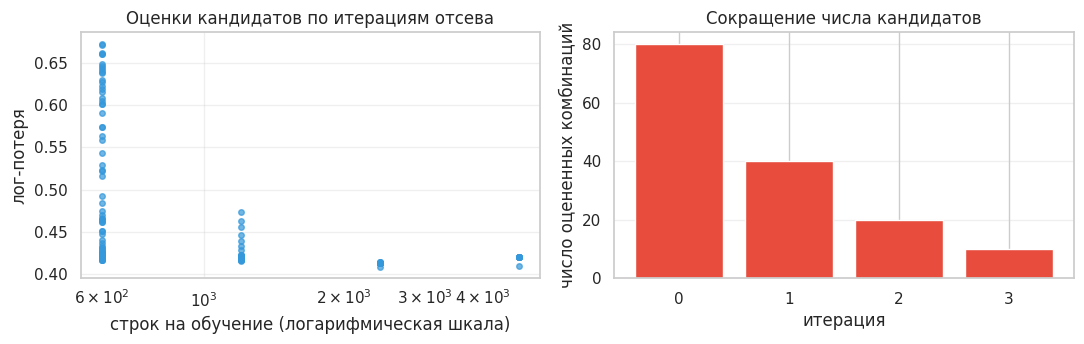

In [15]:
iter_table = (halving_res.groupby('iter')
              .agg(кандидатов=('mean_test_score', 'count'),
                   строк_на_обучение=('n_resources', 'max'),
                   лучшая_оценка=('mean_test_score', 'max'))
              .rename(columns={'строк_на_обучение': 'строк на обучение',
                               'лучшая_оценка': 'лучшая лог-потеря (CV)'})
              .assign(**{'лучшая лог-потеря (CV)': lambda d: -d['лучшая лог-потеря (CV)']}))
display(iter_table)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].scatter(halving_res['n_resources'], -halving_res['mean_test_score'],
                s=16, alpha=0.7, color='#3498db')
axes[0].set_xscale('log')
axes[0].set_xlabel('строк на обучение (логарифмическая шкала)')
axes[0].set_ylabel('лог-потеря')
axes[0].set_title('Оценки кандидатов по итерациям отсева')
axes[0].grid(alpha=0.3)
counts = halving_res.groupby('iter')['mean_test_score'].count()
axes[1].bar(counts.index.astype(str), counts.values, color='#e74c3c')
axes[1].set_xlabel('итерация')
axes[1].set_ylabel('число оцененных комбинаций')
axes[1].set_title('Сокращение числа кандидатов')
axes[1].grid(alpha=0.3, axis='y')
fig.tight_layout()
plt.show()

## **11. Ранний отсев со случайными кандидатами: `HalvingRandomSearchCV`**

Комбинация двух идей: кандидаты извлекаются случайно из непрерывных распределений,
а проверяются с постепенным увеличением данных. Это самый дешёвый из четырёх инструментов,
но и наименее гарантированный: нет ни полного охвата сетки, ни фиксированного числа попыток.


In [16]:
started = time.time()
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    halving_rand = HalvingRandomSearchCV(tuning_pipeline(), param_dist,
                                         n_candidates='exhaust', factor=FACTOR,
                                         min_resources=MIN_RESOURCES,
                                         scoring='neg_log_loss', cv=CV,
                                         random_state=RANDOM_STATE, n_jobs=-1)
    halving_rand.fit(X_train, y_train)
time_halving_rand = time.time() - started

hr_res = pd.DataFrame(halving_rand.cv_results_)
hr_nan = int(hr_res['mean_test_score'].isna().sum())
hr_evals = int(hr_res['mean_test_score'].notna().sum())
tools['HalvingRandomSearchCV'] = {
    'search': halving_rand,
    'оценок комбинаций': hr_evals,
    'обучений': hr_evals * n_folds,
    'время': time_halving_rand,
    'лог-потеря (CV)': -halving_rand.best_score_,
    'параметры': halving_rand.best_params_,
}

print(f'Лучшая комбинация: {halving_rand.best_params_}')
print(f'Лог-потеря на кросс-валидации: {-halving_rand.best_score_:.4f}')
print(f'Кандидатов извлечено: {len(hr_res)}, оценок «комбинация x итерация»: {hr_evals}, '
      f'неопределённых оценок: {hr_nan}, обучений модели: {hr_evals * n_folds}, '
      f'время: {time_halving_rand:.1f} с')
print(f'Итераций отсева: {hr_res["iter"].nunique()}, '
      f'строк на первой итерации: {int(hr_res["n_resources"].min())}, '
      f'на последней: {int(hr_res["n_resources"].max())}')

Лучшая комбинация: {'model__C': np.float64(0.02161894240657444), 'model__l1_ratio': np.float64(0.14286681792194078), 'poly__degree': 1}
Лог-потеря на кросс-валидации: 0.4210
Кандидатов извлечено: 19, оценок «комбинация x итерация»: 19, неопределённых оценок: 0, обучений модели: 95, время: 1.2 с
Итераций отсева: 4, строк на первой итерации: 600, на последней: 4800


## **12. Сводное сравнение четырёх инструментов**

Собираем для каждого инструмента найденные параметры, качество по кросс-валидации,
число оцененных комбинаций, число обучений модели и время. Все четыре обучают итоговую
модель на всей обучающей части (`refit`), поэтому дальше можно один раз посмотреть на
контрольную часть.


In [17]:
def params_text(params):
    return (f"степень {params['poly__degree']}, "
            f"l1_ratio {params['model__l1_ratio']:.3g}, "
            f"C {params['model__C']:.4g}")


def workload(search, n_evals):
    # Стоимость подбора в строках: у раннего отсева обучения идут на части строк,
    # поэтому только число обучений или только время сравнивать некорректно.
    res = pd.DataFrame(search.cv_results_)
    scored = res[res['mean_test_score'].notna()]
    if 'n_resources' in res.columns:
        rows = 0.8 * n_folds * scored['n_resources'].sum()
        unique = int(scored['params'].apply(lambda p: tuple(sorted(p.items()))).nunique())
    else:
        rows = 0.8 * n_folds * n_evals * len(X_train)
        unique = n_evals
    return rows / 1e6, unique


rows = []
for name, t in tools.items():
    workload_mln, unique = workload(t['search'], t['оценок комбинаций'])
    rows.append({
        'инструмент': name,
        'лучшие параметры': params_text(t['параметры']),
        'лог-потеря (CV)': t['лог-потеря (CV)'],
        'уникальных комбинаций': unique,
        'обучений модели': t['обучений'],
        'строк в обучениях, млн': workload_mln,
        'время, с': t['время'],
    })

tools_table = (pd.DataFrame(rows).set_index('инструмент')
               .sort_values('лог-потеря (CV)'))
display(tools_table.round(4))

best_tool = tools_table.index[0]
cv_spread = tools_table['лог-потеря (CV)'].max() - tools_table['лог-потеря (CV)'].min()
print(f'Лучшая лог-потеря на кросс-валидации: {tools_table["лог-потеря (CV)"].iloc[0]:.4f} '
      f'({best_tool})')
print(f'Разброс качества между инструментами: {cv_spread:.4f}')
print(f'Диапазон времени: {tools_table["время, с"].min():.1f} ... '
      f'{tools_table["время, с"].max():.1f} с, '
      f'в {tools_table["время, с"].max() / tools_table["время, с"].min():.1f} раза')
print(f'Диапазон объёма данных в обучениях: {tools_table["строк в обучениях, млн"].min():.2f} ... '
      f'{tools_table["строк в обучениях, млн"].max():.2f} млн строк')

,лучшие параметры,лог-потеря (CV),уникальных комбинаций,обучений модели,"строк в обучениях, млн","время, с"
инструмент,,,,,,
GridSearchCV,"степень 2, l1_ratio 0.75, C 0.03",0.4091,80,400,1.8970,15.7133
HalvingGridSearchCV,"степень 2, l1_ratio 0.5, C 0.03",0.4101,80,750,0.7680,7.9438
RandomizedSearchCV,"степень 2, l1_ratio 0.241, C 0.008386",0.4130,25,125,0.5928,5.0543
HalvingRandomSearchCV,"степень 1, l1_ratio 0.143, C 0.02162",0.4210,9,95,0.1128,1.2269


Лучшая лог-потеря на кросс-валидации: 0.4091 (GridSearchCV)
Разброс качества между инструментами: 0.0120
Диапазон времени: 1.2 ... 15.7 с, в 12.8 раза
Диапазон объёма данных в обучениях: 0.11 ... 1.90 млн строк


In [18]:
test_rows = [base_row, poly_row]
for name, t in tools.items():
    test_rows.append(evaluate(t['search'].best_estimator_, X_test, y_test,
                              f'лучшая по {name}'))

test_table = pd.DataFrame(test_rows).set_index('вариант')
display(test_table.round(4))

print('Подбор шёл только по обучающей части, контрольная использована один раз')
print(f'Лучшая по кросс-валидации: {best_tool} с лог-потерей '
      f'{tools[best_tool]["лог-потеря (CV)"]:.4f}')

tuned_only = test_table.drop(['базовая (стадия 3)', 'полином 2 ст. без штрафа (пайплайн)'])
best_on_test = tuned_only['лог-потеря'].idxmin()
print(f'Лучшая по контрольной части: {best_on_test}')
print(f'Выбор по кросс-валидации и по контрольной части совпал: '
      f'{best_on_test == "лучшая по " + best_tool}')

,ROC-AUC,PR-AUC,метрика Брайера,лог-потеря,F-мера,полнота,точность,доля верных ответов
вариант,,,,,,,,
базовая (стадия 3),0.8788,0.8132,0.1333,0.4257,0.7307,0.6830,0.7856,0.8128
полином 2 ст. без штрафа (пайплайн),0.8770,0.8166,0.1352,0.4294,0.7373,0.7197,0.7557,0.8093
лучшая по GridSearchCV,0.8851,0.8281,0.1299,0.4110,0.7461,0.7197,0.7745,0.8179
лучшая по RandomizedSearchCV,0.8836,0.8257,0.1312,0.4151,0.7405,0.7048,0.7801,0.8164
лучшая по HalvingGridSearchCV,0.8835,0.8263,0.1308,0.4133,0.7427,0.7129,0.7751,0.8164
лучшая по HalvingRandomSearchCV,0.8789,0.8125,0.1334,0.4249,0.7328,0.6830,0.7906,0.8149


Подбор шёл только по обучающей части, контрольная использована один раз
Лучшая по кросс-валидации: GridSearchCV с лог-потерей 0.4091
Лучшая по контрольной части: лучшая по GridSearchCV
Выбор по кросс-валидации и по контрольной части совпал: True


### Вывод по четырём инструментам подбора

| Инструмент | Лог-потеря (CV) | Уникальных комбинаций | Обучений | Строк в обучениях, млн | Время, с |
|---|---|---|---|---|---|
| `GridSearchCV` | **0.4091** | 80 | 400 | 1.8970 | 15.7 |
| `HalvingGridSearchCV` | 0.4101 | 80 | 750 | 0.7680 | 7.9 |
| `RandomizedSearchCV` | 0.4130 | 25 | 125 | 0.5928 | 5.1 |
| `HalvingRandomSearchCV` | 0.4210 | 9 | 95 | **0.1128** | **1.2** |

**По качеству разрыв небольшой, но осмысленный.** Разброс лог-потери CV — **0.0120**.
Первые три инструмента нашли вторую степень полинома и слабый штраф;
`HalvingRandomSearchCV` остановился на первой степени и проиграл 0.0119 — единственный
инструмент, который не добрался до нелинейностей. Причина в числе кандидатов: 9 против 80,
при таком наборе вторая степень могла не попасть в выборку.

**По цене разница в 12.8 раза** — от 1.2 с до 15.7 с, и по объёму данных
от **0.11** до **1.90 млн** строк. Секунды зависят от загрузки машины, поэтому
надёжнее сравнивать число обучений и суммарный объём строк: 95 и 0.11 млн против
400 и 1.90 млн. `GridSearchCV` обработал в 2.5 раза больше строк, чем
`HalvingGridSearchCV`, при той же сетке из 80 комбинаций: ранний отсев снимает
с последних итераций большинство кандидатов.

**Выбор по кросс-валидации и по контрольной части совпал** — впервые за стадии 4–6.
По CV выигрывает `GridSearchCV` (0.4091), по контрольной части он же: лог-потеря 0.4110
против 0.4133 у `HalvingGridSearchCV`, 0.4151 у `RandomizedSearchCV` и 0.4249
у `HalvingRandomSearchCV`. Совпадение объясняется тем, что `GridSearchCV` нашёл лучший
кандидат и по вероятностям, и по разделению: ROC-AUC на контроле 0.8851 против 0.8835
у `HalvingGridSearchCV` и 0.8789 у `HalvingRandomSearchCV`.


## **13. Устойчивость лучшей модели к зерну разбиения**

Кросс-валидация внутри подбора снимает зависимость от одного разбиения, но итоговое
качество на контрольной части — снова одна жеребёвка. Проверим выбранную модель так же,
как модель стадии 3 в блоке 3: десять разных разбиений 75/25, обучение с нуля каждый раз,
оценка на своей контрольной части. Для сравнения — базовая модель стадии 3.


In [19]:
BEST_PARAMS = tools[best_tool]['параметры']


def tuned_pipeline(params):
    # Модель с зафиксированными параметрами: те же шаги, что у пайплайна подбора.
    return Pipeline([
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(degree=params['poly__degree'], include_bias=False)),
        ('model', LogisticRegression(solver='saga', l1_ratio=params['model__l1_ratio'],
                                     C=params['model__C'], max_iter=5000, tol=1e-3,
                                     random_state=RANDOM_STATE)),
    ])


ROBUST_SEEDS = list(range(10))
robust_rows = []
for seed in ROBUST_SEEDS:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.25, stratify=y, random_state=seed
    )
    for name, builder in [('базовая (стадия 3)', base_pipeline),
                          (f'лучшая ({best_tool})', tuned_pipeline)]:
        model = builder(BEST_PARAMS) if name.startswith('лучшая') else builder()
        row = evaluate(model.fit(X_tr, y_tr), X_te, y_te, name)
        row['seed'] = seed
        robust_rows.append(row)

robust = pd.DataFrame(robust_rows)
robust_names = list(robust['вариант'].unique())
robust_summary = robust.groupby('вариант')[METRICS].agg(['mean', 'std', 'min', 'max']).round(4)
display(robust_summary)

for name in robust_names:
    sub = robust[robust['вариант'] == name]
    print(f'{name}: лог-потеря {sub["лог-потеря"].mean():.4f} '
          f'(ср. квадратичное {sub["лог-потеря"].std():.4f}, '
          f'разброс {sub["лог-потеря"].max() - sub["лог-потеря"].min():.4f}), '
          f'доля верных ответов {sub["доля верных ответов"].mean():.4f} '
          f'(разброс {sub["доля верных ответов"].max() - sub["доля верных ответов"].min():.4f})')

доля верных ответов                         ROC-AUC                         лог-потеря                          F-мера                         полнота                        
                                     mean     std     min     max    mean     std     min     max       mean     std     min     max    mean     std     min     max    mean     std     min     max
вариант                                                                                                                                                                                             
базовая (стадия 3)                 0.8181  0.0056  0.8093  0.8280  0.8786  0.0076  0.8677  0.8885     0.4213  0.0113  0.4059  0.4380  0.7373  0.0097  0.7209  0.7543  0.6867  0.0150  0.6626  0.7102
лучшая (GridSearchCV)              0.8220  0.0058  0.8144  0.8326  0.8850  0.0072  0.8758  0.8961     0.4065  0.0112  0.3927  0.4228  0.7476  0.0091  0.7357  0.7641  0.7093  0.0142  0.6912  0.7306

базовая (стадия 3): лог-потеря 0.4213 (ср. квадратичное 0.0113, разброс 0.0321), доля верных ответов 0.8181 (разброс 0.0187)
лучшая (GridSearchCV): лог-потеря 0.4065 (ср. квадратичное 0.0112, разброс 0.0301), доля верных ответов 0.8220 (разброс 0.0182)


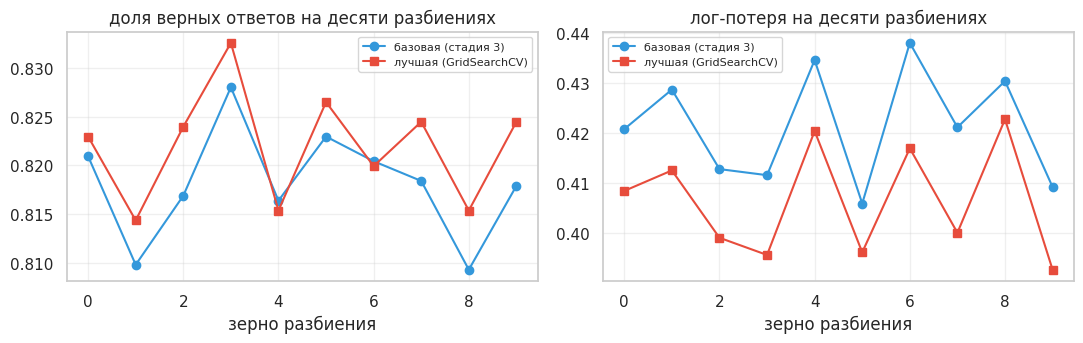

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, metric, colors in [(axes[0], 'доля верных ответов', ['#3498db', '#e74c3c']),
                           (axes[1], 'лог-потеря', ['#3498db', '#e74c3c'])]:
    for name, color, marker in zip(robust_names, colors, ['o', 's']):
        sub = robust[robust['вариант'] == name]
        ax.plot(ROBUST_SEEDS, sub[metric], marker=marker, color=color, label=name)
    ax.set_title(f'{metric} на десяти разбиениях')
    ax.set_xlabel('зерно разбиения')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Вывод по устойчивости модели

| Модель | Доля верных ответов | ROC-AUC | Лог-потеря | F-мера | Полнота |
|---|---|---|---|---|---|
| базовая (стадия 3) | 0.8181 ± 0.0056 | 0.8786 ± 0.0076 | 0.4213 ± 0.0113 | 0.7373 ± 0.0097 | 0.6867 ± 0.0150 |
| лучшая (`GridSearchCV`) | **0.8220 ± 0.0058** | **0.8850 ± 0.0072** | **0.4065 ± 0.0112** | **0.7476 ± 0.0091** | **0.7093 ± 0.0142** |

Лучшая модель выигрывает у базовой по всем пяти метрикам на десяти разбиениях.
Средняя лог-потеря ниже на **0.0148**, ROC-AUC выше на **0.0064**, полнота — на **0.0226**.
Разбросы почти совпадают (0.0112 против 0.0113 по лог-потере), поэтому выигрыш
не куплен ценой устойчивости.

Диапазоны: у базовой модели лог-потеря 0.4059–0.4380, у лучшей 0.3927–0.4228.
Худшее разбиение лучшей модели (0.4228) почти совпадает со средним у базовой (0.4213):
на неудачной жеребьёвке преимущество почти исчезает. Доля верных ответов:
0.8093–0.8280 у базовой против 0.8144–0.8326 у лучшей.


In [21]:
# Порог выбирается по out-of-fold вероятностям обучающей части: контроль не участвует
best_params = tools[best_tool]['параметры']
best_pipe = tuned_pipeline(best_params)
oof_proba = cross_val_predict(best_pipe, X_train, y_train, cv=CV,
                              method='predict_proba', n_jobs=-1)[:, 1]

THR_GRID = np.round(np.arange(0.05, 0.96, 0.01), 2)
price_rows = []
for fn_cost in [1, 2, 3, 5]:
    costs = []
    for t in THR_GRID:
        pred = (oof_proba >= t).astype(int)
        fn = int(((y_train == 1) & (pred == 0)).sum())
        fp = int(((y_train == 0) & (pred == 1)).sum())
        costs.append((fn_cost * fn + fp) / len(y_train))
    best_t = float(THR_GRID[int(np.argmin(costs))])
    pred = (oof_proba >= best_t).astype(int)
    price_rows.append({
        'цена пропуска : цена тревоги': f'{fn_cost} : 1',
        'порог': best_t,
        'F-мера (train, out-of-fold)': f1_score(y_train, pred),
        'полнота': recall_score(y_train, pred),
        'точность': precision_score(y_train, pred),
    })
display(pd.DataFrame(price_rows).set_index('цена пропуска : цена тревоги').round(4))

f1_curve = [f1_score(y_train, (oof_proba >= t).astype(int)) for t in THR_GRID]
best_thr = float(THR_GRID[int(np.argmax(f1_curve))])
print(f'Порог по максимуму F-меры: {best_thr:.2f} (F-мера на train {max(f1_curve):.4f})')

test_proba = best_pipe.fit(X_train, y_train).predict_proba(X_test)[:, 1]
for t in [0.5, best_thr, 0.34]:
    pred = (test_proba >= t).astype(int)
    print(f'порог {t:.2f}: F-мера {f1_score(y_test, pred):.4f}, '
          f'полнота {recall_score(y_test, pred):.4f}, '
          f'точность {precision_score(y_test, pred):.4f}, '
          f'доля верных ответов {accuracy_score(y_test, pred):.4f}')


,порог,"F-мера (train, out-of-fold)",полнота,точность
цена пропуска : цена тревоги,,,,
1 : 1,0.51,0.7480,0.7007,0.8022
2 : 1,0.34,0.7609,0.8190,0.7105
3 : 1,0.28,0.7524,0.8580,0.6700
5 : 1,0.18,0.7116,0.9170,0.5814


Порог по максимуму F-меры: 0.38 (F-мера на train 0.7627)


порог 0.50: F-мера 0.7461, полнота 0.7197, точность 0.7745, доля верных ответов 0.8179
порог 0.38: F-мера 0.7593, полнота 0.7918, точность 0.7293, доля верных ответов 0.8134
порог 0.34: F-мера 0.7593, полнота 0.8177, точность 0.7087, доля верных ответов 0.8073


### Вывод по порогу решения

Порог подобран по out-of-fold вероятностям обучающей части — контрольная часть
в выборе не участвовала.

| Цена пропуска : цена тревоги | Порог | F-мера (train, out-of-fold) | Полнота | Точность |
|---|---|---|---|---|
| 1 : 1 | 0.51 | 0.7480 | 0.7007 | 0.8022 |
| 2 : 1 | **0.34** | **0.7609** | 0.8190 | 0.7105 |
| 3 : 1 | 0.28 | 0.7524 | 0.8580 | 0.6700 |
| 5 : 1 | 0.18 | 0.7116 | 0.9170 | 0.5814 |

Порог по максимуму F-меры — **0.38** (F-мера на обучающей части 0.7627). Он близок
к оптимуму по цене ошибки 2:1 (0.34) и к порогам стадий 3 и 4 (0.34 и 0.35): соотношение
«пропуск вдвое дороже ложной тревоги» устойчиво даёт порог в районе 0.34–0.38 независимо
от модели и числа признаков.

На контрольной части:

| Порог | F-мера | Полнота | Точность | Доля верных ответов |
|---|---|---|---|---|
| 0.50 (по умолчанию) | 0.7461 | 0.7197 | 0.7745 | 0.8179 |
| 0.38 (максимум F-меры) | **0.7593** | 0.7918 | 0.7293 | 0.8134 |
| 0.34 (цена 2:1) | **0.7593** | **0.8177** | 0.7087 | 0.8073 |

Снижение порога с 0.5 до 0.38 поднимает F-меру на **0.0132** (0.7593 против 0.7461)
и полноту на **0.0721**. Дальнейшее снижение до 0.34 оставляет F-меру той же, но меняет
баланс: полнота растёт до 0.8177, точность падает до 0.7087. Если пропуск события дороже
ложной тревоги, выбирается 0.34; если важнее не тревожить лишний раз — 0.38.


## **14. Модель, которую предлагаем применить**

| Модель | ROC-AUC | Лог-потеря | F-мера (порог 0.5) | Доля верных ответов |
|---|---|---|---|---|
| логистическая регрессия (стадия 3) | 0.8788 | 0.4257 | 0.7307 | 0.8128 |
| полином 2 ст. + L1, `C = 0.1` (стадия 4) | 0.8819 | 0.4162 | 0.7495 | 0.8194 |
| полином 2 ст. + ElasticNet, `C = 0.03` (стадии 4 и 5) | 0.8834 | 0.4133 | 0.7404 | 0.8149 |
| **`GridSearchCV`: степень 2, `l1_ratio = 0.75`, `C = 0.03` (стадия 6)** | **0.8851** | **0.4110** | **0.7461** | 0.8179 |

**Рекомендация: логистическая регрессия SAGA внутри пайплайна
`StandardScaler → PolynomialFeatures → LogisticRegression` со степенью полинома 2,
`l1_ratio = 0.75` и `C = 0.03`** — вариант, найденный `GridSearchCV`.

**Обоснование:**

1. Лучшая лог-потеря кросс-валидации (**0.4091**) и лучшая лог-потеря на контрольной
   части (**0.4110**) среди всех четырёх инструментов.
2. Лучший ROC-AUC на контрольной части (**0.8851**) — выше стадии 4 (0.8834)
   и стадии 3 (0.8788).
3. Устойчивость подтверждена на десяти разбиениях: лог-потеря **0.4065 ± 0.0112**
   против **0.4213 ± 0.0113** у базовой модели.
4. Модель оформлена пайплайном: предобработка обучается внутри каждого блока проверки,
   объект переносится в эксплуатацию целиком.

Порог решения — отдельная настройка, в пайплайн он не входит. Для этой модели порог 0.38
даёт F-меру 0.7593, порог 0.34 — ту же F-меру при полноте 0.8177. Правило выбора
порога по цене ошибки переносится с стадий 3 и 4 без изменений.


## **15. Выводы**

### Что сделано

Стадия 6 собрала разрозненные приёмы проверки и подбора в один воспроизводимый объект —
пайплайн — и на нём ответила на три вопроса стадии. Цель — бинарная `Event`
(0 — жив со своей печенью, 1 — трансплантация или смерть).

**1. Насколько устойчива оценка качества к случайности.**

| Проверка | Результат |
|---|---|
| 20 разбиений 75/25 | доля верных 0.8093–0.8280 (разброс **0.0187**, std 0.0049); ROC-AUC 0.8677–0.8965 (разброс **0.0288**); лог-потеря 0.3954–0.4380 (разброс **0.0427**, std 0.0105); полнота 0.6612–0.7129 (разброс **0.0517**) |
| Основное разбиение (seed 42) | доля верных 0.8128 — хуже 2 разбиений из 20; лог-потеря 0.4257 — хуже 5 из 20 |
| Три выборки 50/25/25 | потеряно **1 976 строк** (33 %), разрыв обучение−контроль по лог-потере 0.0197 |

**2. Как устроены схемы кросс-валидации и что даёт пайплайн.**

- `StratifiedKFold` держит долю события стабильнее `KFold` в **31 раз** (std 0.00015 против 0.00476).
- `LeaveOneOut` даёт близкую долю верных (0.8050 против 0.8000) ценой **1 186**-кратного роста числа обучений.
- `RepeatedStratifiedKFold` уточняет ошибку среднего в **3.55 раза** (0.0113 → 0.0032).
- Пайплайн эквивалентен ручной предобработке: совпали все 8 метрик стадии 3.
- Утечка масштабирования не обнаружилась (0.00000), а утечка **отбора по цели** — да:
  **−0.01158** на 300 строках против −0.00001 на 5 928.

**3. Чем отличаются инструменты подбора.**

| Инструмент | Лог-потеря CV | Обучений | Время, с |
|---|---|---|---|
| `GridSearchCV` | **0.4091** | 400 | 15.7 |
| `HalvingGridSearchCV` | 0.4101 | 750 | 7.9 |
| `RandomizedSearchCV` | 0.4130 | 125 | 5.1 |
| `HalvingRandomSearchCV` | 0.4210 | 95 | 1.2 |

Разброс качества — **0.0120**, разница времени — **в 12.8 раза** (секунды зависят
от загрузки машины, надёжнее мерить обучениями и объёмом строк: 95 обучений и 0.11 млн
строк против 400 и 1.90 млн). Три инструмента из четырёх нашли вторую степень полинома;
`HalvingRandomSearchCV` с девятью кандидатами до неё не добрался.

**4. Стартовый объём для раннего отсева.** При бинарной цели неопределённых оценок нет
ни при одном старте от 50 до 600 строк: событий 37.2 %, и даже в блоке из 10 строк
ожидается 3–4 события. Прежнее ограничение по редкому классу снялось. Старт 600 строк
оставлен по другой причине: при 50, 100 и 300 строках отсев систематически выбирает
первую степень с лог-потерей 0.4187–0.4207, и только с 600 строк кандидат со степенью 2
получает достаточно данных, чтобы выиграть (0.4101). Мало данных на первых итерациях
не убивает класс, а искажает сравнение моделей разной сложности.

### Итоговая рекомендация

**Логистическая регрессия SAGA внутри пайплайна
`StandardScaler → PolynomialFeatures → LogisticRegression` со степенью полинома 2,
`l1_ratio = 0.75` и `C = 0.03`** (вариант `GridSearchCV`): ROC-AUC 0.8851, лог-потеря
0.4110, F-мера 0.7461 при пороге 0.5 и 0.7593 при пороге 0.38, полнота 0.7197
и 0.7918 соответственно, доля верных ответов 0.8179.

На десяти разбиениях модель превосходит базовую по всем метрикам: ROC-AUC
**0.8850 ± 0.0072** против 0.8786 ± 0.0076, лог-потеря **0.4065 ± 0.0112** против
0.4213 ± 0.0113, полнота **0.7093 ± 0.0142** против 0.6867 ± 0.0150.

Главный методический итог стадии: **разброс от выбора разбиения (0.0427 по лог-потере)
в 3.6 раза больше разницы между инструментами подбора (0.0120)**. Сравнивать инструменты
по одному разбиению нельзя; сравнение по кросс-валидации и проверка на десяти разбиениях
дают согласованный ответ.

### Глоссарий терминов

| Термин | Что означает | Зачем нужен |
|---|---|---|
| **Пайплайн (`Pipeline`)** | Цепочка «преобразования + модель» в одном объекте | Предобработка обучается внутри каждого блока проверки, модель переносится целиком |
| **`make_pipeline`** | Короткая форма: шаги называются автоматически | Удобно для одинаковых шагов без ручной нумерации |
| **`poly__degree`, `model__C`** | Имя параметра с префиксом шага пайплайна | Говорит перебору, какой шаг настраивать |
| **Зерно случайности (`random_state`)** | Начальное значение генератора случайных чисел | Делает прогон повторяемым; сравнения корректны |
| **`KFold`** | Разбиение на блоки без учёта классов | Просто, но доля класса в блоках колеблется |
| **`StratifiedKFold`** | Разбиение с сохранением доли каждого класса | Оценка стабильна: доля события 37.2 % воспроизводится точно |
| **`LeaveOneOut`** | Проверка по одной строке, обучение n раз | Максимально точная оценка ценой n обучений; неприменима на тысячах строк |
| **`RepeatedStratifiedKFold`** | Несколько независимых разбиений k-fold подряд | Уточняет среднюю оценку и показывает разброс |
| **Ошибка среднего** | Разброс блоков, делённый на корень из их числа | Показывает, насколько доверять средней оценке |
| **`GridSearchCV`** | Полный перебор заданных комбинаций | Гарантия, что оптимум сетки не пропущен; дорого при трёх параметрах |
| **`RandomizedSearchCV`** | Случайная выборка комбинаций из распределений | Охватывает непрерывные параметры за фиксированную цену |
| **`loguniform`** | Равномерное распределение по логарифму параметра | `C` меняется на порядки, искать нужно пропорционально шкале |
| **`HalvingGridSearchCV`** | Перебор с ранним отсевом слабых кандидатов | Дешевле полной сетки при том же охвате комбинаций |
| **`HalvingRandomSearchCV`** | Случайные кандидаты с ранним отсевом | Самый быстрый инструмент, без гарантий по охвату |
| **`factor`, `min_resources`** | Шаг увеличения данных и стартовый объём | Задают агрессивность отсева |
| **`refit`** | Переобучение лучшей конфигурации на всех данных подбора | Даёт готовую модель `best_estimator_` |
| **Утечка предобработки** | Статистики преобразования посчитаны по строкам проверки | Занижает оценку лог-потери; устраняется пайплайном |
| **Лог-потеря** | Штраф за уверенность в неверном ответе | Критерий подбора: оценивает вероятности, а не только классы |
| **Порог решения** | Граница вероятности, выше которой прогноз считается событием | Настраивается отдельно от модели по цене пропуска и ложной тревоги |
